# 03 · EDA, resultados y cartel

Todo lo visual del proyecto, como **preguntas**. Cada figura que va al cartel se guarda en `salidas/cartel/`, y al final se arma el `.pptx`.

| # | Pregunta | Va al cartel |
|---|---|---|
| 1 | ¿Cuántos accidentes hay y cuándo ocurren? | |
| 2 | ¿Por qué solo Guadalajara, Zapopan y Tlaquepaque? | |
| 3 | ¿Están concentrados en pocos lugares? | texto de la introducción |
| 4 | ¿Cómo se ve una celda por dentro? | Metodología |
| 5 | ¿La lluvia aumenta los accidentes? | Resultados |
| 6 | ¿Qué modelo ubica mejor las zonas de riesgo? | Resultados |
| 7 | ¿Qué pesa más y qué aumenta el riesgo? | Resultados |
| 8 | ¿Dónde está el riesgo en López Mateos? | Resultados |
| 9 | Diagrama de la metodología y armado del cartel | todo |

**Entra:** lo que guardaron el 00, el 01 y el 02, más `data/osm/zmg_osm.gpkg` y `Plantilla_Poster_MCD.pptx`.

In [21]:
import logging
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
import geopandas as gpd, pygeohash as pgh, statsmodels.api as sm, statsmodels.formula.api as smf
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from shapely.geometry import box

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # sin avisos de fuentes

PLANTILLA = "Plantilla_Poster_MCD.pptx"
SALIDA_CARTEL = "Cartel_TOG.pptx"
OUT = Path("salidas/cartel"); OUT.mkdir(parents=True, exist_ok=True)
UTM = "EPSG:32613"

# Estilo de las figuras (tamaño de impresión: CM = 1 centímetro)
CM = 1 / 2.54
INK, INK2, GRID, GRIS = "#0b0b0b", "#52514e", "#e4e3df", "#c3c2b7"
AZUL, AZUL_CLARO, NARANJA, NAVY = "#2a78d6", "#9ec5f4", "#eb6834", "#003C68"
mpl.rcParams.update({"font.family": ["Liberation Sans", "Arial", "DejaVu Sans"], "font.size": 13, "axes.titlesize": 15,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
                     "axes.axisbelow": True, "figure.dpi": 70, "savefig.dpi": 300, "savefig.bbox": "tight"})

def guardar(fig, nombre):
    fig.savefig(OUT / nombre); plt.show()

acc = pd.read_csv("data/accidentes_zmg.csv", parse_dates=["FECHA"])
acc_cel = pd.read_csv("data/accidentes_celdas.csv", parse_dates=["FECHA"])
celdas = pd.read_csv("data/celdas.csv")

## 1. ¿Cuántos accidentes hay y cuándo ocurren?

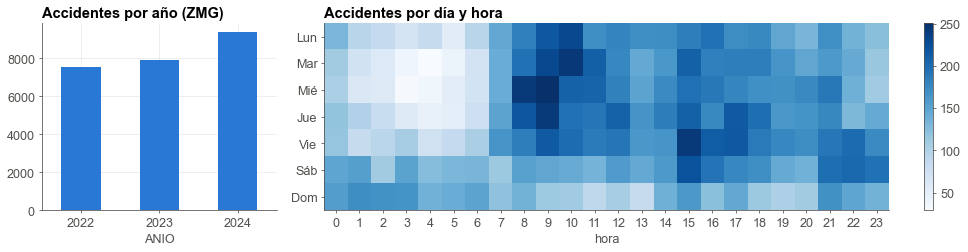

CLASE
Solo daños     86.9
Con heridos    10.9
Fatal           2.3


In [2]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 3]})
acc.groupby("ANIO").size().plot(kind="bar", ax=ax[0], color=AZUL, rot=0, title="Accidentes por año (ZMG)")
calor = pd.crosstab(acc.FECHA.dt.dayofweek, acc.HORA)
im = ax[1].imshow(calor, aspect="auto", cmap="Blues"); ax[1].grid(False)
ax[1].set(yticks=range(7), yticklabels=dias, xticks=range(24), xlabel="hora", title="Accidentes por día y hora")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()
print(acc.CLASE.map({1: "Fatal", 2: "Con heridos", 3: "Solo daños"}).value_counts(normalize=True).mul(100).round(1).to_string())

**Qué vemos:**
- 2024 sube, en buena parte por un cambio de registro.
- Hay dos picos, en la mañana y a media tarde, más las **madrugadas de fin de semana**.
- La gran mayoría de los accidentes son solo daños.

## 2. ¿Por qué solo Guadalajara, Zapopan y Tlaquepaque?

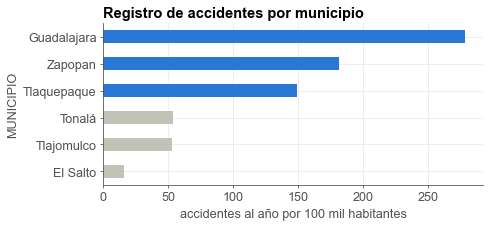

Celdas por municipio:
municipio                      buen_registro
El Salto                       0                 310
Guadalajara                    1                1618
Ixtlahuacán de los Membrillos  0                   6
Tlajomulco                     0                 927
Tlaquepaque                    1                 768
Tonalá                         0                 389
Zapopan                        1                1757


In [3]:
POBLACION_2020 = {"Guadalajara": 1385629, "Zapopan": 1476491, "Tlaquepaque": 687127, "Tonalá": 569913,
                  "Tlajomulco": 727750, "El Salto": 232852}
tasa = acc.groupby("MUNICIPIO").size().loc[list(POBLACION_2020)] / acc.ANIO.nunique() / pd.Series(POBLACION_2020) * 1e5
ax = tasa.sort_values().plot(kind="barh", figsize=(7, 3), color=[AZUL if m in ["Guadalajara", "Zapopan", "Tlaquepaque"] else GRIS
                                                                    for m in tasa.sort_values().index])
ax.set(xlabel="accidentes al año por 100 mil habitantes", title="Registro de accidentes por municipio"); plt.show()
print("Celdas por municipio:"); print(celdas.groupby(["municipio", "buen_registro"]).size().to_string())

**Qué vemos:** Tonalá, Tlajomulco y El Salto registran muchos menos accidentes por habitante. Lo más probable es que reporten menos. Las celdas en azul son las de **buen registro**, y solo esas entran al modelo.

## 3. ¿Están concentrados en pocos lugares?

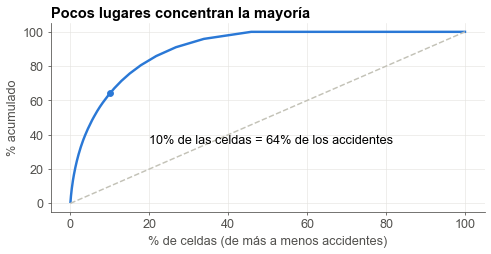

Accidentes sobre avenidas principales: 16,607 de 24,872 (67%)


In [4]:
por_celda = acc_cel.groupby("gh7").size().reindex(celdas.gh7, fill_value=0).sort_values(ascending=False)
concentracion = por_celda.iloc[:int(len(por_celda) * .10)].sum() / por_celda.sum()
acumulado = por_celda.cumsum().values / por_celda.sum() * 100
x = np.arange(1, len(por_celda) + 1) / len(por_celda) * 100
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(x, acumulado, color=AZUL, lw=2.5); ax.plot([0, 100], [0, 100], color=GRIS, ls="--")
ax.scatter([10], [concentracion * 100], color=AZUL, zorder=3)
ax.annotate(f"10% de las celdas = {concentracion:.0%} de los accidentes", (10, concentracion * 100), xytext=(20, 35))
ax.set(xlabel="% de celdas (de más a menos accidentes)", ylabel="% acumulado", title="Pocos lugares concentran la mayoría")
plt.show()
print(f"Accidentes sobre avenidas principales: {len(acc_cel):,} de {len(acc):,} ({len(acc_cel) / len(acc):.0%})")

**Ojo, no confundir:** este número es **descriptivo**: viendo hacia atrás, el 10% de celdas con más choques de 2022–2024 tiene esa parte de los accidentes. El 58% del modelo (pregunta 6) es **predictivo**: elige su 10% solo con 2022–2023 y se mide en 2024.

## 4. ¿Cómo se ve una celda por dentro?
Ejemplo: **López Mateos × Mariano Otero** (`9ewmqyw`). El mapa muestra lo que el 01 "ve" en esa celda, y abajo está su fila en `celdas.csv`. Así una esquina se convierte en números.

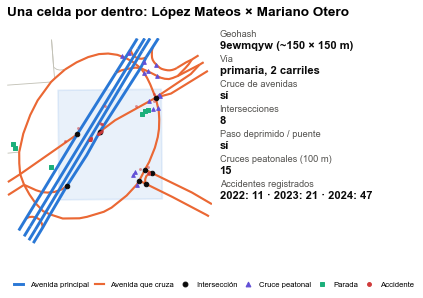

,lat,lon,via_principal,via_nombre,clase_via,carriles_via,vel_max_via,puente,tunel,n_avenidas,...,n_100m_cruce_peatonal,n_100m_parada,n_100m_semaforo,n_100m_servicio,semaforo,cruce_avenidas,dist_centro_km,mpio,municipio,buen_registro
valor,20.646744,-103.40538,lopez mateos,Avenida Adolfo López Mateos Sur,2.0,2.0,60.0,0,1,4,...,15,7,5,18,1,1,6.881877,120,Zapopan,1


In [8]:
GH, NOMBRE = "9ewmqyw", "López Mateos × Mariano Otero"
lat, lon, dlat, dlon = pgh.decode_exactly(GH)
caja = gpd.GeoSeries([box(lon - dlon, lat - dlat, lon + dlon, lat + dlat)], crs="EPSG:4326").to_crs(UTM).iloc[0]
zona = caja.buffer(70)
leer = lambda capa: gpd.read_file("data/osm/zmg_osm.gpkg", layer=capa, bbox=(lon - .004, lat - .004, lon + .004, lat + .004)).to_crs(UTM)
vias, aristas, nodos, pois = leer("vias"), leer("aristas"), leer("nodos"), leer("pois")
fila = celdas.set_index("gh7").loc[GH]
es_ppal = vias.name.fillna("").str.contains("L[OÓ]PEZ MATEOS|JIQUILPAN", case=False, regex=True)
choques = acc_cel[acc_cel.gh7 == GH]
pts = gpd.GeoSeries(gpd.points_from_xy(choques.LONGITUD, choques.LATITUD), crs="EPSG:4326").to_crs(UTM)

fig = plt.figure(figsize=(13.3 * CM, 9.6 * CM))
ax = fig.add_axes([0, 0, .56, .9]); tx = fig.add_axes([.58, 0, .42, .9]); tx.axis("off")
gpd.GeoSeries([caja], crs=UTM).plot(ax=ax, color=AZUL, alpha=.1, edgecolor=AZUL, lw=1.8)
aristas.clip(zona).plot(ax=ax, color=GRIS, lw=.9)
vias[~es_ppal].clip(zona).plot(ax=ax, color=NARANJA, lw=2.2)
vias[es_ppal].clip(zona).plot(ax=ax, color=AZUL, lw=3)
p = pois[pois.within(zona)]
p[p.tipo == "cruce_peatonal"].plot(ax=ax, color="#6250d6", marker="^", markersize=14, zorder=4)
p[p.tipo == "parada"].plot(ax=ax, color="#1baf7a", marker="s", markersize=14, zorder=4)
nodos[nodos.within(caja) & (nodos.street_count >= 3)].plot(ax=ax, color=INK, markersize=22, zorder=5)
ax.scatter(pts.x, pts.y, s=9, color="#d03b3b", alpha=.55, linewidths=0, zorder=6)
x0, y0, x1, y1 = zona.bounds
ax.set(xlim=(x0, x1), ylim=(y0, y1), xticks=[], yticks=[], xlabel="", ylabel="", aspect="equal"); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.text(0, .97, f"Una celda por dentro: {NOMBRE}", fontsize=14, fontweight="bold", va="top")
anual = choques.groupby("ANIO").size()
datos = [("Geohash", f"{GH} (~150 × 150 m)"),
         ("Vía", f"{ {1: 'secundaria', 2: 'primaria', 3: 'troncal', 4: 'autopista'}[int(fila.clase_via)]}, {int(fila.carriles_via)} carriles"),
         ("Cruce de avenidas", "sí" if fila.cruce_avenidas else "no"), ("Intersecciones", f"{int(fila.n_intersecciones)}"),
         ("Paso deprimido / puente", "sí" if fila.tunel or fila.puente else "no"),
         ("Cruces peatonales (100 m)", f"{int(fila.n_100m_cruce_peatonal)}"),
         ("Accidentes registrados", " · ".join(f"{a}: {anual.get(a, 0)}" for a in (2022, 2023, 2024)))]
for i, (k, v) in enumerate(datos):
    tx.text(0, .98 - i * .105, k, fontsize=9.5, color=INK2, va="top")
    tx.text(0, .935 - i * .105, v, fontsize=11.5, fontweight="bold", color=INK, va="top")
fig.legend(handles=[Line2D([], [], color=AZUL, lw=3, label="Avenida principal"), Line2D([], [], color=NARANJA, lw=2.2, label="Avenida que cruza"),
                    Line2D([], [], marker="o", color=INK, lw=0, ms=5, label="Intersección"),
                    Line2D([], [], marker="^", color="#6250d6", lw=0, ms=5, label="Cruce peatonal"),
                    Line2D([], [], marker="s", color="#1baf7a", lw=0, ms=5, label="Parada"),
                    Line2D([], [], marker="o", color="#d03b3b", lw=0, ms=4, label="Accidente")],
           loc="lower left", bbox_to_anchor=(0, -.12), ncol=6, fontsize=8, frameon=False, handlelength=1.2, columnspacing=.8)
guardar(fig, "f2_celda_ejemplo.png")
fila.to_frame("valor").T

## 5. ¿La lluvia aumenta los accidentes?
Se arma una tabla **por hora** (26,304 horas de 2022–2024) con los accidentes de toda la ZMG y la lluvia de esa hora.

Comparar horas con y sin lluvia no basta: llueve más en verano y en las tardes, cuando hay más tráfico. Por eso la regresión de Poisson **controla hora del día, día de la semana, mes y año**. Así cada hora lluviosa se compara con horas secas equivalentes (por ejemplo, martes de julio a las 7 pm).

**RR (razón de tasas):** 1.30 = 30% más accidentes que una hora seca equivalente. **p < 0.05** = no parece casualidad.

In [9]:
clima_h = pd.read_csv("data/clima_horario.csv", parse_dates=["fecha_hora"])
acc["fecha_hora"] = acc.FECHA + pd.to_timedelta(acc.HORA, unit="h")
h = clima_h.set_index("fecha_hora").join(acc.groupby("fecha_hora").size().rename("accidentes")).fillna({"accidentes": 0}).reset_index()
h = h[h.fecha_hora.dt.year.between(2022, 2024)]
h["hora"], h["dow"], h["mes"], h["anio"] = h.fecha_hora.dt.hour, h.fecha_hora.dt.dayofweek, h.fecha_hora.dt.month, h.fecha_hora.dt.year
h["lluvia"] = pd.cut(h.precipitacion_mm, [-.1, .49, 2, 5, 1e3], labels=["seco", "ligera", "moderada", "fuerte"])
modelo_lluvia = smf.glm("accidentes ~ C(lluvia) + C(hora) * C(dow) + C(mes) + C(anio)", data=h,
                        family=sm.families.Poisson()).fit(cov_type="HC0")
lluvia = pd.DataFrame({k: {"horas": int((h.lluvia == k).sum()), "RR": np.exp(modelo_lluvia.params[f"C(lluvia)[T.{k}]"]),
                           "p": modelo_lluvia.pvalues[f"C(lluvia)[T.{k}]"]} for k in ["ligera", "moderada", "fuerte"]}).T
lluvia.round(3)

,horas,RR,p
ligera,536.0,1.046,0.330
moderada,177.0,1.025,0.759
fuerte,58.0,1.283,0.049


**Ojo:**
- Hay pocas horas de lluvia fuerte (decenas en tres años), así que el resultado es **preliminar**.
- La lluvia se mide en un solo punto de la ciudad: puede llover en Zapopan y no en el centro. Eso, si acaso, **diluye** el efecto real.

## 6. ¿Qué modelo ubica mejor las zonas de riesgo? (resultados del 02)

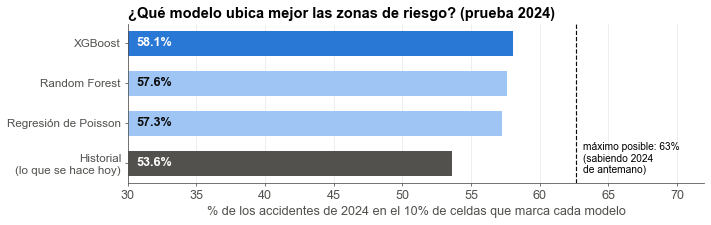

In [10]:
modelos = pd.read_csv("data/resultados_modelos.csv", index_col="modelo")
resumen = pd.read_csv("data/resumen_modelos.csv", index_col="clave").valor
maximo = resumen["maximo"]
m = modelos.drop(index=[i for i in modelos.index if i.startswith("Máximo")]).sort_values("Captura @10% celdas")
v = m["Captura @10% celdas"].to_numpy() * 100
col = [AZUL if k == "XGBoost" else INK2 if k == "Historial" else AZUL_CLARO for k in m.index]

fig, ax = plt.subplots(figsize=(27 * CM, 7.5 * CM))
ax.barh(range(len(m)), v, color=col, height=.62)
for i, x in enumerate(v):
    ax.text(30.6, i, f"{x:.1f}%", va="center", fontsize=13, fontweight="bold", color=INK if col[i] == AZUL_CLARO else "white")
ax.axvline(maximo * 100, color=INK, ls="--", lw=1.2)
ax.text(maximo * 100 + .5, -.3, f"máximo posible: {maximo:.0%}\n(sabiendo 2024\nde antemano)", fontsize=10.5, va="bottom")
ax.set_yticks(range(len(m))); ax.set_yticklabels([k + "\n(lo que se hace hoy)" if k == "Historial" else k for k in m.index], fontsize=12)
ax.set(xlim=(30, 72), xlabel="% de los accidentes de 2024 en el 10% de celdas que marca cada modelo",
       title="¿Qué modelo ubica mejor las zonas de riesgo? (prueba 2024)")
ax.grid(axis="y", visible=False)
guardar(fig, "f3_comparativa.png")

## 7. ¿Qué pesa más y qué aumenta el riesgo?

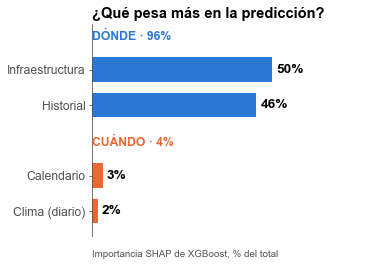

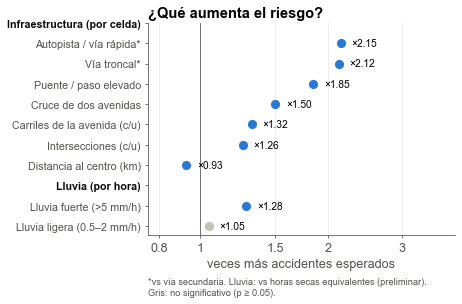

In [11]:
imp = pd.read_csv("data/importancia.csv").groupby("bloque")["%"].sum()
donde = (imp["Infraestructura"] + imp["Historial"]) / 100
fig, ax = plt.subplots(figsize=(12.6 * CM, 10 * CM))
y = np.array([4.2, 3.2, 1.2, .2])
bloques = [("Infraestructura", "Infraestructura", AZUL), ("Historial", "Historial", AZUL),
           ("Calendario", "Calendario", NARANJA), ("Clima", "Clima (diario)", NARANJA)]
ax.barh(y, [imp[k] for k, _, _ in bloques], color=[c for *_, c in bloques], height=.7)
for yi, (k, _, _) in zip(y, bloques):
    ax.text(imp[k] + 1.2, yi, f"{imp[k]:.0f}%", va="center", fontsize=14, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels([e for _, e, _ in bloques], fontsize=12.5)
ax.text(0, 5.05, f"DÓNDE · {donde:.0%}", fontsize=12.5, fontweight="bold", color=AZUL)
ax.text(0, 2.05, f"CUÁNDO · {1 - donde:.0%}", fontsize=12.5, fontweight="bold", color=NARANJA)
ax.set(xlim=(0, 75), ylim=(-.5, 5.5), xticks=[], title="¿Qué pesa más en la predicción?")
ax.grid(False); ax.spines["bottom"].set_visible(False)
ax.text(0, -.1, "Importancia SHAP de XGBoost, % del total", transform=ax.transAxes, fontsize=10, color=INK2)
guardar(fig, "f4_que_pesa.png")

rr = pd.read_csv("data/rr_infraestructura.csv", index_col="clave")
claves = ["via_autopista", "via_troncal", "puente", "cruce_avenidas", "carriles_via", "n_intersecciones", "dist_centro_km"]
filas = [("Infraestructura (por celda)", None, None)] + [(rr.at[k, "variable"], rr.at[k, "RR"], rr.at[k, "p"]) for k in claves]
filas += [("Lluvia (por hora)", None, None)] + [(f"Lluvia {k} ({e})", lluvia.at[k, "RR"], lluvia.at[k, "p"])
                                                for k, e in [("fuerte", ">5 mm/h"), ("ligera", "0.5–2 mm/h")]]
fig, ax = plt.subplots(figsize=(14.4 * CM, 10 * CM))
yy = np.arange(len(filas))[::-1]
for yi, (nombre, valor, p) in zip(yy, filas):
    if valor is not None:
        ax.scatter(valor, yi, s=70, color=AZUL if p < .05 else GRIS, zorder=3)
        ax.text(valor * 1.06, yi, f"×{valor:.2f}", va="center", fontsize=10.5)
ax.set_yticks(yy); ax.set_yticklabels([f[0] for f in filas], fontsize=11)
for lab in ax.get_yticklabels():
    if lab.get_text().startswith(("Infraestructura", "Lluvia (")):
        lab.set_fontweight("bold"); lab.set_color(INK)
ax.axvline(1, color=INK2, lw=.8); ax.set_xscale("log"); ax.set_xticks([.8, 1, 1.5, 2, 3])
ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g")); ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set(xlim=(.75, 4), xlabel="veces más accidentes esperados", title="¿Qué aumenta el riesgo?")
ax.text(0, -.2, "*vs vía secundaria. Lluvia: vs horas secas equivalentes (preliminar).\nGris: no significativo (p ≥ 0.05).",
        transform=ax.transAxes, fontsize=9.5, color=INK2, va="top")
ax.grid(axis="y", visible=False)
guardar(fig, "f5_factores.png")

## 8. ¿Dónde está el riesgo en López Mateos?

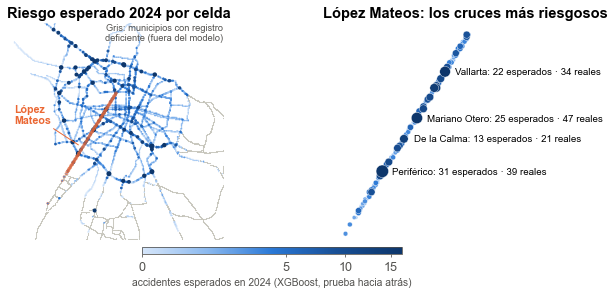

In [13]:
CRUCES_LM = {"9ewmq2y": "Periférico", "9ewmx7e": "Vallarta", "9ewmqyw": "Mariano Otero", "9ewmqu2": "De la Calma", "9ewmxxm": "Américas"}
c = pd.read_csv("data/prediccion_celdas_2024.csv")
otros = celdas[celdas.buen_registro == 0]
cmap = mpl.colors.LinearSegmentedColormap.from_list("b", ["#d6e6fa", "#8bb9ef", AZUL, "#184f95", "#0d366b"])
norm = mpl.colors.PowerNorm(.5, vmin=0, vmax=np.percentile(c.xgb_2024, 99.5))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(27 * CM, 12.4 * CM))
o = c.sort_values("xgb_2024")
a1.scatter(otros.lon, otros.lat, s=1.2, c=GRIS, linewidths=0)
sc = a1.scatter(o.lon, o.lat, s=1.5 + o.xgb_2024.clip(upper=25), c=o.xgb_2024, cmap=cmap, norm=norm, linewidths=0)
lm = c[c.es_lopez_mateos == 1]
a1.scatter(lm.lon, lm.lat, s=5, facecolors="none", edgecolors=NARANJA, linewidths=.45)
a1.annotate("López\nMateos", (-103.425, 20.625), xytext=(-103.52, 20.655), color=NARANJA, fontsize=11, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=NARANJA))
a1.text(1, 1, "Gris: municipios con registro\ndeficiente (fuera del modelo)", transform=a1.transAxes, fontsize=9.5, color=INK2, ha="right", va="top")
a1.set(aspect=1.07, xlim=(-103.53, -103.22), ylim=(20.5, 20.79), title="Riesgo esperado 2024 por celda")
s = lm.sort_values("xgb_2024")
a2.scatter(s.lon, s.lat, s=10 + 5 * s.xgb_2024, c=s.xgb_2024, cmap=cmap, norm=norm, edgecolors="white", linewidths=.4)
for _, f in lm.nlargest(8, "xgb_2024").iterrows():
    if f.gh7 in CRUCES_LM:
        a2.annotate(f"{CRUCES_LM[f.gh7]}: {f.xgb_2024:.0f} esperados · {f.real_2024:.0f} reales", (f.lon, f.lat),
                    xytext=(10, -3), textcoords="offset points", fontsize=10)
a2.set(aspect=1.07, xlim=(-103.465, -103.33), ylim=(20.575, 20.703), title="López Mateos: los cruces más riesgosos")
for a in (a1, a2):
    a.set(xticks=[], yticks=[]); a.grid(False)
    for sp in a.spines.values():
        sp.set_visible(False)
cb = fig.colorbar(sc, ax=[a1, a2], orientation="horizontal", shrink=.45, pad=.03, aspect=35)
cb.set_label("accidentes esperados en 2024 (XGBoost, prueba hacia atrás)", fontsize=10.5)
guardar(fig, "f6_mapa.png")

## 9. Diagrama de la metodología y armado del cartel

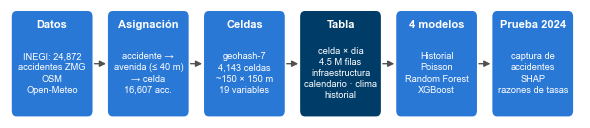

In [14]:
pasos = [("Datos", f"INEGI: {len(acc):,}\naccidentes ZMG\nOSM\nOpen-Meteo"),
         ("Asignación", f"accidente →\navenida (≤ 40 m)\n→ celda\n{len(acc_cel):,} acc."),
         ("Celdas", f"geohash-7\n{int(resumen.n_celdas):,} celdas\n~150 × 150 m\n19 variables"),
         ("Tabla", "celda × día\n4.5 M filas\ninfraestructura\ncalendario · clima\nhistorial"),
         ("4 modelos", "Historial\nPoisson\nRandom Forest\nXGBoost"),
         ("Prueba 2024", "captura de\naccidentes\nSHAP\nrazones de tasas")]
fig, ax = plt.subplots(figsize=(27 * CM, 5.4 * CM))
ax.set(xlim=(0, 6), ylim=(0, 1)); ax.axis("off")
for i, (t, d) in enumerate(pasos):
    ax.add_patch(FancyBboxPatch((i + .05, .04), .84, .92, boxstyle="round,pad=0,rounding_size=0.05", fc=NAVY if i == 3 else AZUL, ec="none"))
    ax.text(i + .47, .84, t, ha="center", va="center", color="white", fontsize=11.5, fontweight="bold")
    ax.text(i + .47, .42, d, ha="center", va="center", color="white", fontsize=9.5, linespacing=1.3)
    if i < 5:
        ax.annotate("", (i + 1.05, .5), (i + .89, .5), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.4))
guardar(fig, "f1_metodologia.png")

### Números del cartel
Todo el texto del cartel sale de aquí. Si vuelves a correr el 02, el cartel se actualiza solo.

In [18]:
pip install pptx

ERROR: Could not find a version that satisfies the requirement pptx (from versions: none)
ERROR: No matching distribution found for pptx
Note: you may need to restart the kernel to use updated packages.


In [19]:
cap_xgb, cap_hist = modelos.at["XGBoost", "Captura @10% celdas"], modelos.at["Historial", "Captura @10% celdas"]
extra = (cap_xgb - cap_hist) * resumen.accidentes_2024
fuerte = lluvia.loc["fuerte"]
hay_lluvia = fuerte.p < .05
top_lm = [CRUCES_LM[g] for g in lm.sort_values("xgb_2024", ascending=False).gh7 if g in CRUCES_LM][:3]
pd.Series({"XGBoost captura": f"{cap_xgb:.1%}", "Historial captura": f"{cap_hist:.1%}", "máximo posible": f"{maximo:.1%}",
           "accidentes más cubiertos": f"{extra:.0f}", "pesa el lugar": f"{donde:.0%}", "lluvia fuerte": f"{(fuerte.RR - 1) * 100:+.0f}% (p = {fuerte.p:.3f})",
           "concentración": f"{concentracion:.0%}", "cruces LM": ", ".join(top_lm)}).to_frame("valor")

,valor
XGBoost captura,58.1%
Historial captura,53.6%
máximo posible,62.7%
accidentes más cubiertos,250
pesa el lugar,96%
lluvia fuerte,+28% (p = 0.049)
concentración,64%
cruces LM,"Periférico, Mariano Otero, Vallarta"


### Armar el `.pptx`
Llena la plantilla del ITESO: textos, recuadros y figuras. No necesitas leer este código; solo corre la celda y abre `Cartel_TOG.pptx`.

In [23]:
from lxml import etree
from PIL import Image
from pptx import Presentation
from pptx.dml.color import RGBColor
from pptx.enum.shapes import MSO_SHAPE
from pptx.enum.text import MSO_ANCHOR, PP_ALIGN
from pptx.oxml.ns import qn
from pptx.util import Cm, Pt

NAVY_RGB, TINTE = RGBColor(0x00, 0x3C, 0x68), RGBColor(0xE6, 0xEE, 0xF6)

def todas(shapes):
    for sh in shapes:
        yield from (todas(sh.shapes) if sh.shape_type == 6 else [sh])

def llenar(shape, parrafos, tam=22, alinear=PP_ALIGN.JUSTIFY, despues=6):
    tf = shape.text_frame; tf.clear()
    for i, par in enumerate(parrafos):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        vineta = isinstance(par, tuple) and par[0] == "•"
        runs = par[1] if vineta else par
        runs = [(runs, False, False)] if isinstance(runs, str) else runs
        p.alignment, p.space_after = (PP_ALIGN.LEFT if vineta else alinear), Pt(despues)
        if vineta:
            pPr = p._p.get_or_add_pPr(); pPr.set("marL", str(Cm(.8))); pPr.set("indent", str(-Cm(.6)))
            etree.SubElement(pPr, qn("a:buFont"), typeface="Arial"); etree.SubElement(pPr, qn("a:buChar"), char="•")
        for texto, neg, cur in runs:
            r = p.add_run(); r.text = texto; r.font.size, r.font.bold, r.font.italic = Pt(tam), neg, cur

def imagen(slide, nombre, x, y, w):
    ancho, alto = Image.open(OUT / nombre).size
    slide.shapes.add_picture(str(OUT / nombre), Cm(x), Cm(y), Cm(w), Cm(w * alto / ancho))
    return w * alto / ancho

def recuadro(slide, x, y, w, h, parrafos, centrado=False):
    s = slide.shapes.add_shape(MSO_SHAPE.ROUNDED_RECTANGLE, Cm(x), Cm(y), Cm(w), Cm(h))
    s.adjustments[0] = .08; s.fill.solid(); s.fill.fore_color.rgb = TINTE; s.line.fill.background(); s.shadow.inherit = False
    tf = s.text_frame; tf.word_wrap = True; tf.vertical_anchor = MSO_ANCHOR.MIDDLE
    for i, runs in enumerate(parrafos):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.alignment = PP_ALIGN.CENTER if centrado else PP_ALIGN.LEFT
        for texto, t, neg in runs:
            r = p.add_run(); r.text = texto; r.font.size, r.font.bold = Pt(t), neg; r.font.color.rgb = NAVY_RGB

def mover(shape, arriba, alto=None):
    shape.top = Cm(arriba)
    if alto is not None:
        shape.height = Cm(alto)

prs = Presentation(PLANTILLA); slide = prs.slides[0]
caja = {sh.name: sh for sh in todas(slide.shapes)}
for k in ["CuadroTexto 45", "CuadroTexto 30"]:
    for p in caja[k].text_frame.paragraphs:
        for r in p.runs:
            r.text = r.text.replace("2025", "2026")

# Encabezado
tf = caja["CuadroTexto 47"].text_frame
for p in list(tf.paragraphs)[1:]:
    p._p.getparent().remove(p._p)
tf.paragraphs[0].runs[0].text = "Riesgo vial en avenidas principales de la ZMG: dónde y cuándo, con aprendizaje automático. Caso Av. López Mateos"
tf.paragraphs[0].runs[0].font.size = Pt(34)
lineas = list(caja["CuadroTexto 15"].text_frame.paragraphs)
lineas[0].runs[0].text, lineas[0].runs[1].text = "Edgar Quintero, ", "[correo]@iteso.mx"
lineas[1].runs[0].text, lineas[1].runs[1].text = "[Nombre del Director TOG], ", "[correo]@iteso.mx"
if len(lineas) > 2:
    lineas[2]._p.getparent().remove(lineas[2]._p)

# Resumen + 3 números
mover(caja["CuadroTexto 113"], 18.4, 7.6)
llenar(caja["CuadroTexto 113"], [
    f"Se construyó una tabla celda × día que integra, para {int(resumen.n_celdas):,} celdas geohash de ~150 m sobre las avenidas "
    "principales de Guadalajara, Zapopan y Tlaquepaque y cada día de 2022–2024, los accidentes del INEGI, 19 variables de "
    "infraestructura de OpenStreetMap, el calendario, la lluvia y el historial de cada celda. Se compararon cuatro modelos, del "
    "conteo histórico a XGBoost, entrenando con 2022–2023 y probando con 2024. XGBoost ubica mejor las zonas de riesgo que el "
    "conteo histórico y el riesgo depende sobre todo del lugar" +
    (f"; la lluvia fuerte se asocia con {(fuerte.RR - 1) * 100:+.0f}% de accidentes por hora." if hay_lluvia else ".")])
tercera = ((f"{(fuerte.RR - 1) * 100:+.0f}%", "accidentes en horas con lluvia fuerte (preliminar)") if hay_lluvia
           else (f"+{extra:.0f}", "accidentes cubiertos vs el conteo histórico"))
for i, (num, txt) in enumerate([(f"{cap_xgb:.0%}", "de los accidentes de 2024 en el 10% de celdas que marca el modelo"),
                                (f"{donde:.0%}", "del riesgo lo explica el lugar (infraestructura + historial)"), tercera]):
    recuadro(slide, 1.5 + i * 9.2, 26.3, 8.6, 4.2, [[(num, 44, True)], [(txt, 16, False)]], centrado=True)

# Introducción
mover(caja["Rectángulo 28"], 31.4); mover(caja["CuadroTexto 29"], 33.3, 10.2)
llenar(caja["CuadroTexto 29"], [
    "En la ZMG se registran más de 8 mil siniestros viales al año y el riesgo está muy concentrado: el 10% de las celdas de "
    f"avenidas principales reúne el {concentracion:.0%} de los accidentes. Para decidir dónde intervenir suele contarse cuántos "
    "accidentes hubo en cada punto, pero ese conteo no explica por qué un cruce es peligroso ni cuándo, y sufre de regresión a "
    "la media: un mal año no hace peligroso a un sitio."])
recuadro(slide, 1.5, 39.5, 27, 3.6, [[("Pregunta de investigación: ", 20, True),
    ("¿Qué tan bien se puede anticipar dónde y cuándo ocurren los accidentes en las avenidas principales de la ZMG con "
     "infraestructura, calendario, clima e historial, y qué factores pesan más?", 20, False)]])

# Metodología
mover(caja["Rectángulo 32"], 44.6)
met = caja["CuadroTexto 33"]; mover(met, 46.6, 29.7)
y = 46.9 + imagen(slide, "f1_metodologia.png", 1.5, 46.9, 27) + .4
h_cel = imagen(slide, "f2_celda_ejemplo.png", 1.3, y, 15.2)
geo = slide.shapes.add_textbox(Cm(16.8), Cm(y), Cm(12), Cm(h_cel)); geo.text_frame.word_wrap = True
llenar(geo, [[("¿Por qué celdas geohash-7? [3]", True, False)],
             ("•", "Miden lo mismo en toda la ciudad: conteos comparables, sin depender de límites administrativos [4]."),
             ("•", "~150 m ≈ un cruce y su zona de influencia (76 m en el HSM [1])."),
             ("•", "Jerárquicas: los primeros 5 caracteres dan el bloque de ~5 km que contiene la celda."),
             ("•", "Estándar y reproducibles; ya usadas para predecir accidentes [5].")], tam=18, alinear=PP_ALIGN.LEFT, despues=5)
met.text_frame.margin_top = Cm(y + h_cel + .3 - 46.6)
llenar(met, [
    ("•", [("Datos: ", True, False), ("ATUS-INEGI 2022–2024, OpenStreetMap con OSMnx [8] (vías, intersecciones, semáforos, puentes, "
                                     "paradas, comercios) y lluvia horaria de Open-Meteo.", False, False)]),
    ("•", [("Transformaciones: ", True, False), ("coordenadas a UTM (metros); cada accidente a la avenida más cercana (≤ 40 m) y a "
            "su celda; conteo por celda y día; historial de los 365 y 90 días previos; lluvia por hora → indicadores diarios; "
            "calendario (festivos, quincena); 2 variables redundantes fuera (correlación 0.99).", False, False)]),
    ("•", [("Modelos: ", True, False), ("Historial (promedio de la celda), regresión de Poisson [2], Random Forest y XGBoost "
                                       "Poisson [6].", False, False)]),
    ("•", [("Evaluación: ", True, False), ("entrenamiento abr 2022 – dic 2023, prueba 2024; % de accidentes capturados en el "
                                          "10% de celdas marcadas; importancia SHAP [7].", False, False)])], tam=20, despues=5)

# Resultados
y = 18.7 + imagen(slide, "f3_comparativa.png", 31.5, 18.7, 27) + .3
recuadro(slide, 31.5, y, 27, 2.3, [[("XGBoost vs conteo histórico: ", 18, True),
    (f"{(cap_xgb - cap_hist) * 100:+.1f} puntos ≈ {extra:.0f} accidentes más ubicados en 2024 con las mismas "
     f"{int(resumen.celdas_10pct)} celdas.", 18, False)]])
y += 2.7
y += max(imagen(slide, "f4_que_pesa.png", 31.2, y, 12.6), imagen(slide, "f5_factores.png", 44.2, y, 14.6)) + .4
y += imagen(slide, "f6_mapa.png", 31.5, y, 27) + .3
mover(caja["CuadroTexto 36"], 18.4, y - 18.4); llenar(caja["CuadroTexto 36"], [""])
y += .6

# Conclusiones y trabajo a futuro
mover(caja["Rectángulo 38"], y); mover(caja["CuadroTexto 41"], y + 1.9, 66.9 - (y + 1.9))
llenar(caja["CuadroTexto 41"], [
    ("•", f"El riesgo es sobre todo de lugar: infraestructura e historial explican el {donde:.0%} de la predicción."),
    ("•", f"XGBoost ubica el {cap_xgb:.0%} de los accidentes de 2024 en el 10% de las celdas, contra {cap_hist:.0%} del conteo "
          f"histórico; el máximo posible es {maximo:.0%}."),
    ("•", "Vías rápidas, puentes, cruces de avenidas, más carriles e intersecciones elevan el riesgo" +
          (f"; la lluvia fuerte, {(fuerte.RR - 1) * 100:+.0f}% por hora (preliminar)." if hay_lluvia else ".")),
    ("•", f"En López Mateos destacan los cruces con {', '.join(top_lm[:-1])} y {top_lm[-1]}."),
    ("•", "El cambio de registro de 2024 afecta el nivel, no el orden de las celdas, que es lo que se evalúa.")], tam=21, despues=4)
mover(caja["Rectángulo 44"], 67.6); mover(caja["CuadroTexto 46"], 69.5, 6.8)
llenar(caja["CuadroTexto 46"], [
    ("•", "Lluvia por zona y por hora (varios puntos de Open-Meteo o NASA IMERG) dentro del modelo principal."),
    ("•", "Volumen de tráfico: aforos (transparencia) y aproximaciones (centralidad de la red, rutas GTFS)."),
    ("•", "Sensibilidad (tamaño de celda, buffer, Tonalá) y pronóstico 2025 cuando el INEGI lo publique.")], tam=21, despues=4)

# Agradecimientos y referencias
llenar(caja["CuadroTexto 70"], [[("El autor agradece al ", False, True), ("Instituto Tecnológico y de Estudios Superiores de Occidente", True, True),
    (" (ITESO) por la formación recibida, a [Nombre del Director TOG] por su guía, y al ", False, True), ("INEGI", True, True),
    (" y a la comunidad de ", False, True), ("OpenStreetMap", True, True), (" por los datos abiertos que hicieron posible este trabajo.", False, True)]],
    alinear=PP_ALIGN.LEFT)
llenar(caja["CuadroTexto 67"], [
    "[1] AASHTO, Highway Safety Manual, 1st ed. Washington, DC, 2010.",
    "[2] D. Lord y F. Mannering, “The statistical analysis of crash-frequency data,” Transp. Res. A, 44(5), 2010.",
    "[3] G. Niemeyer, Geohash, geohash.org, 2008.",
    "[4] S. Openshaw, The Modifiable Areal Unit Problem. Norwich: Geo Books, 1984.",
    "[5] S. Moosavi et al., “Accident risk prediction based on heterogeneous sparse data,” ACM SIGSPATIAL, 2019.",
    "[6] T. Chen y C. Guestrin, “XGBoost: A scalable tree boosting system,” ACM SIGKDD, 2016.",
    "[7] S. M. Lundberg y S.-I. Lee, “A unified approach to interpreting model predictions,” NeurIPS, 2017.",
    "[8] G. Boeing, “OSMnx,” Comput. Environ. Urban Syst., vol. 65, pp. 126–139, 2017."], tam=15, alinear=PP_ALIGN.LEFT, despues=0)

prs.save(SALIDA_CARTEL)
print("→", SALIDA_CARTEL)

ModuleNotFoundError: No module named 'pptx'